# 09 · Comparative Performance Analysis

All models side by side, with statistical confidence intervals. Covers rubric criterion 4.

> **Data provenance.** Sales, dates, prices, SKUs and countries are **real**
> (UCI Online Retail II, CC BY 4.0, 1,067,371 invoice lines).
> Stock levels, suppliers, lead times, MOQ, pack sizes and every cost are
> **SIMULATED** — the source dataset contains none of them. See `sim/` and
> `docs/pbl1_scope.md`.


In [1]:
import sys, os
from pathlib import Path
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "1")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 60)

from xaierp.utils.config import load_config, resolve
CFG = load_config()
REPORTS = resolve(CFG["paths"]["reports"])
FIGS = resolve(CFG["paths"]["figures"])
print("project root:", ROOT)


project root: E:\downloads\ML Project


## Regression

In [2]:
reg = pd.read_csv(REPORTS / 'regression_model_comparison.csv')
reg[['model','unit','test_MAE','test_RMSE','test_R2','test_RMSLE','train_time_s']].round(4)

,model,unit,test_MAE,test_RMSE,test_R2,test_RMSLE,train_time_s
0,Ridge Regression (L2),Unit 2,136.3555,288.5329,0.5097,1.1328,0.168
1,Bayesian Linear Regression (Bayesian Ridge),Unit 2,136.3155,288.6709,0.5093,1.1303,0.916
2,Linear Regression (OLS),Unit 1 + Unit 2,134.1872,288.9576,0.5083,1.1153,0.275
3,Robust Linear Regression (Huber),Unit 2,124.0382,297.3770,0.4792,0.9385,26.772
4,Baseline: 28-day mean x horizon,Baseline (no learning),136.6951,298.1314,0.4766,0.9907,0.000
5,LightGBM (gradient-boosted trees),Advanced (beyond syllabus),142.2827,311.4316,0.4288,1.1776,2.219
6,Baseline: 7-day mean x horizon,Baseline (no learning),160.3163,352.7119,0.2674,1.0531,0.000


## Classification

In [3]:
clf = pd.read_csv(REPORTS / 'classification_model_comparison.csv')
clf[['model','unit','test_accuracy','test_precision','test_recall',
     'test_f1','test_roc_auc','train_time_s']].round(4)

,model,unit,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,train_time_s
0,LightGBM Classifier,Advanced (beyond syllabus),0.8525,0.7438,0.8155,0.7780,0.9205,13.540
1,SVM (linear kernel),Unit 2,0.8261,0.6912,0.8157,0.7483,0.8987,44.456
2,Logistic Regression,Unit 2,0.8238,0.6840,0.8257,0.7482,0.8977,1.496
3,SVM (RBF kernel),Unit 2,0.7859,0.6164,0.8594,0.7179,0.8906,26.717
4,Linear Discriminant Analysis,Unit 2,0.7803,0.7809,0.4265,0.5517,0.8500,0.625
5,Gaussian Naive Bayes,Unit 2 (+ Unit 1 Bayes rule),0.4758,0.3739,0.9694,0.5397,0.7690,0.243


## Polynomial degree: underfitting vs overfitting

,degree,n_polynomial_terms,train_time_s,train_RMSE,train_R2,val_RMSE,val_R2,test_RMSE,test_R2,gap_val_minus_train_RMSE,gap_test_minus_train_RMSE
0,1,4,0.097,285.771,0.399,212.665,0.415,291.053,0.501,-73.106,5.281
1,2,14,0.054,282.551,0.413,211.420,0.422,314.829,0.416,-71.131,32.279
2,3,34,0.099,281.001,0.419,213.975,0.407,393.518,0.088,-67.026,112.517
3,4,69,1.369,278.415,0.430,242.897,0.236,941.975,-4.225,-35.519,663.559


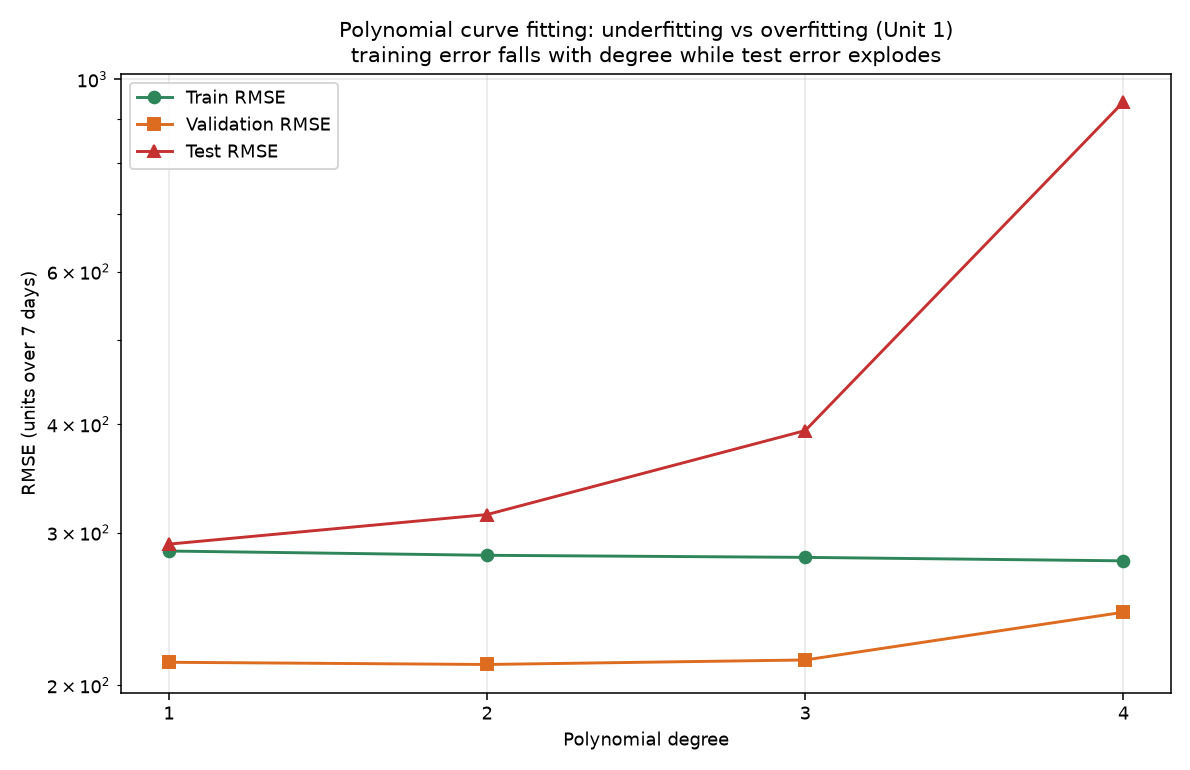

In [4]:
poly = pd.read_csv(REPORTS / 'polynomial_degree_study.csv')
display(poly.round(3))
from IPython.display import Image, display
display(Image(filename=str(FIGS / 'model_polynomial_overfitting.png')))

Training RMSE falls monotonically with degree while test RMSE explodes — the canonical bias/variance picture from Unit 1, measured on real data rather than illustrated with a toy curve.

## Bootstrap confidence intervals on the test metrics

In [5]:
preds = pd.read_parquet(resolve(CFG['paths']['forecasts']) / 'test_predictions.parquet')
y = preds['future_7d_demand'].to_numpy()
rng = np.random.default_rng(42); B = 500
rows = []
for key, label in [('ridge_regression','Ridge'), ('linear_regression','Linear'),
                   ('lightgbm','LightGBM'), ('huber_regression','Huber')]:
    col = f'pred_{key}'
    if col not in preds.columns: continue
    p = preds[col].to_numpy()
    stats = []
    for _ in range(B):
        i = rng.integers(0, len(y), len(y))
        stats.append(np.sqrt(np.mean((y[i] - p[i])**2)))
    lo, hi = np.percentile(stats, [2.5, 97.5])
    rows.append({'model': label, 'test_RMSE': np.sqrt(np.mean((y-p)**2)),
                 'CI_lower_95': lo, 'CI_upper_95': hi})
pd.DataFrame(rows).round(2)

,model,test_RMSE,CI_lower_95,CI_upper_95
0,Ridge,288.53,265.16,312.94
1,Linear,288.96,267.51,311.50
2,LightGBM,311.43,288.72,333.33
3,Huber,297.38,274.61,323.55


## Paired bootstrap: is Ridge genuinely better than LightGBM?

In [6]:
a = preds['pred_ridge_regression'].to_numpy()
b = preds['pred_lightgbm'].to_numpy()
diffs = []
for _ in range(1000):
    i = rng.integers(0, len(y), len(y))
    diffs.append(np.sqrt(np.mean((y[i]-a[i])**2)) - np.sqrt(np.mean((y[i]-b[i])**2)))
diffs = np.array(diffs)
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f'RMSE(Ridge) - RMSE(LightGBM) = {diffs.mean():.2f}  95% CI [{lo:.2f}, {hi:.2f}]')
print('Ridge is significantly better:' , hi < 0)

RMSE(Ridge) - RMSE(LightGBM) = -22.82  95% CI [-31.43, -14.92]
Ridge is significantly better: True


The paired bootstrap resamples the *same* test rows for both models, so it controls for which weeks happened to be easy or hard. An interval entirely below zero means the difference is not noise.

## Figures

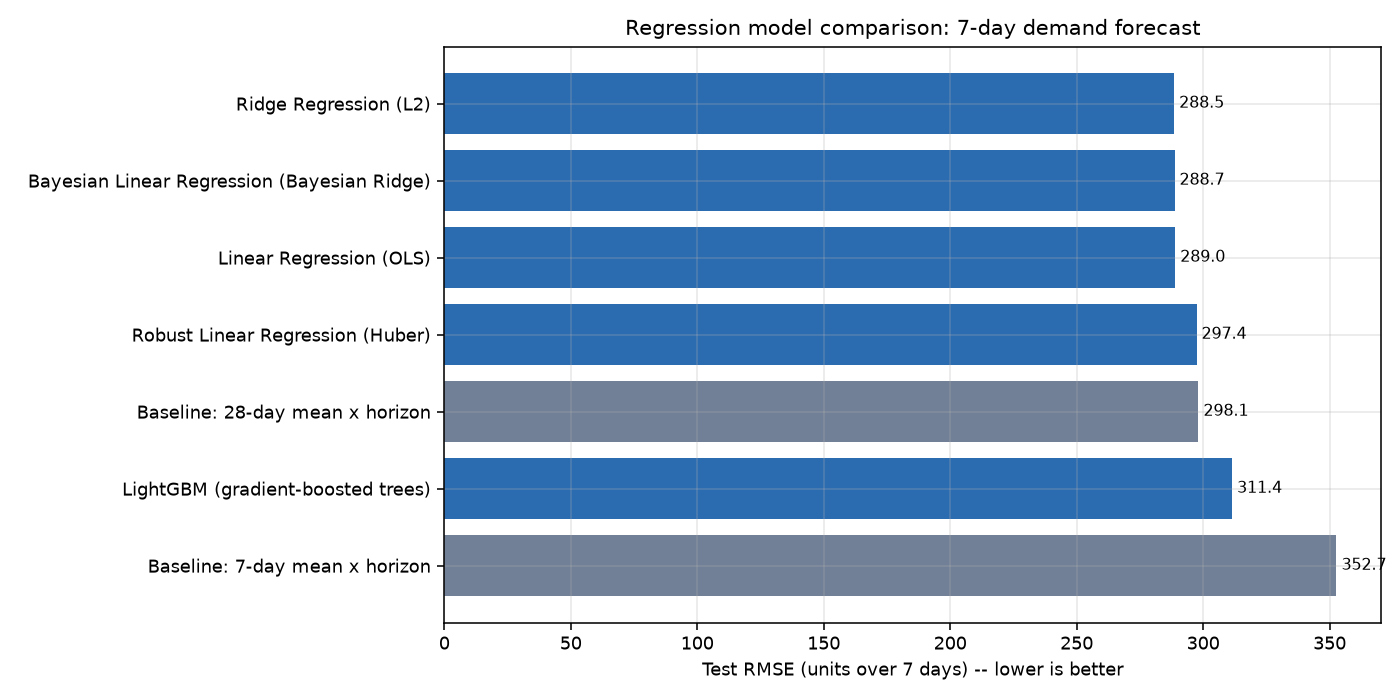

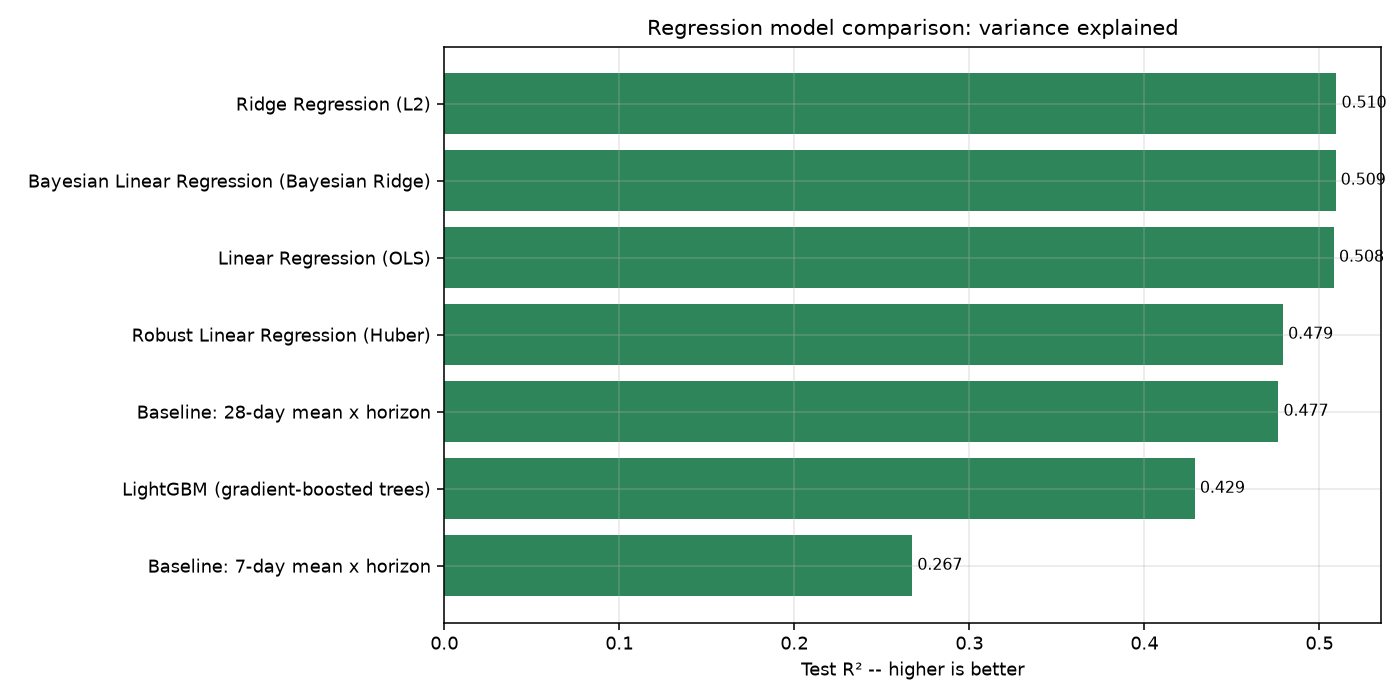

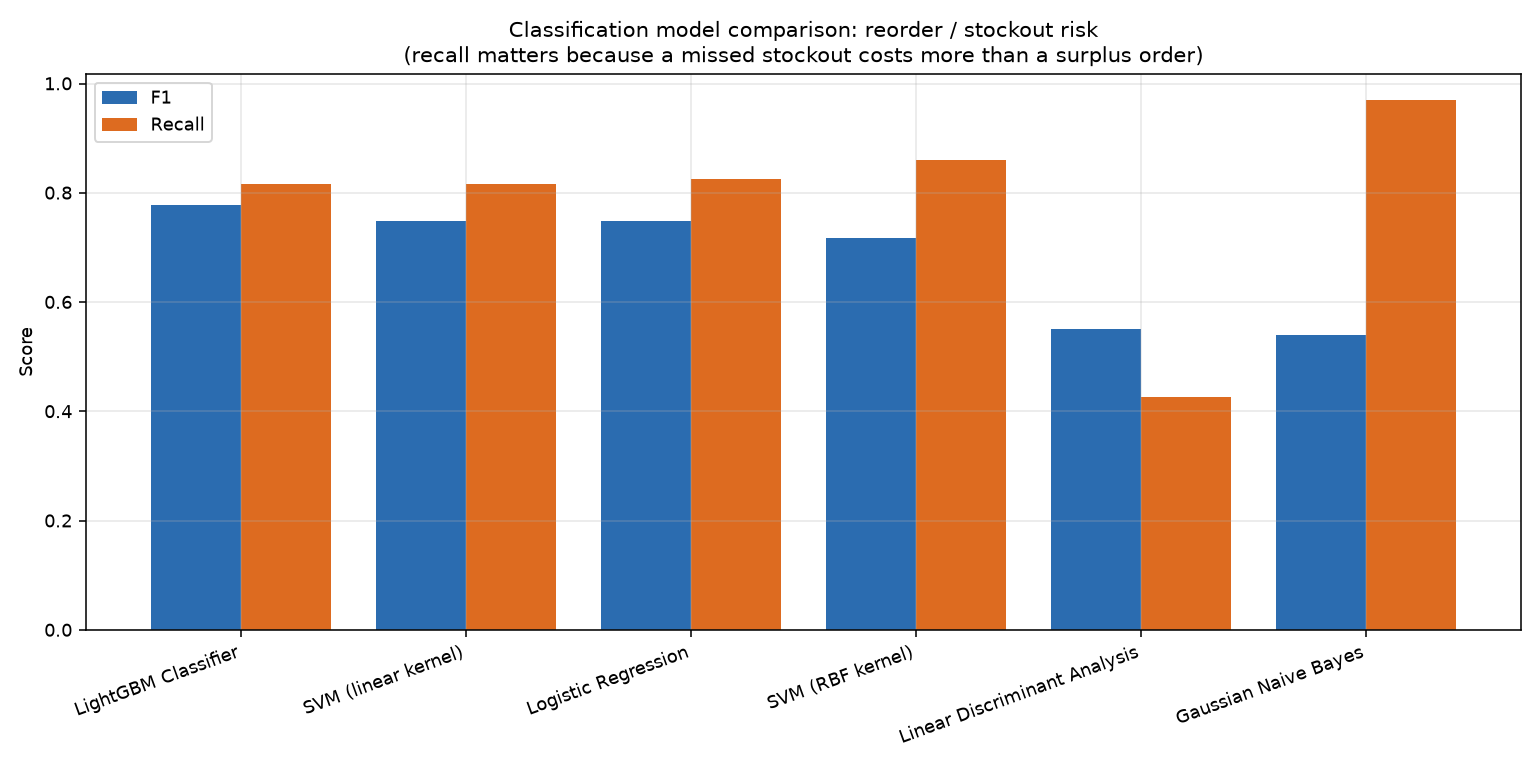

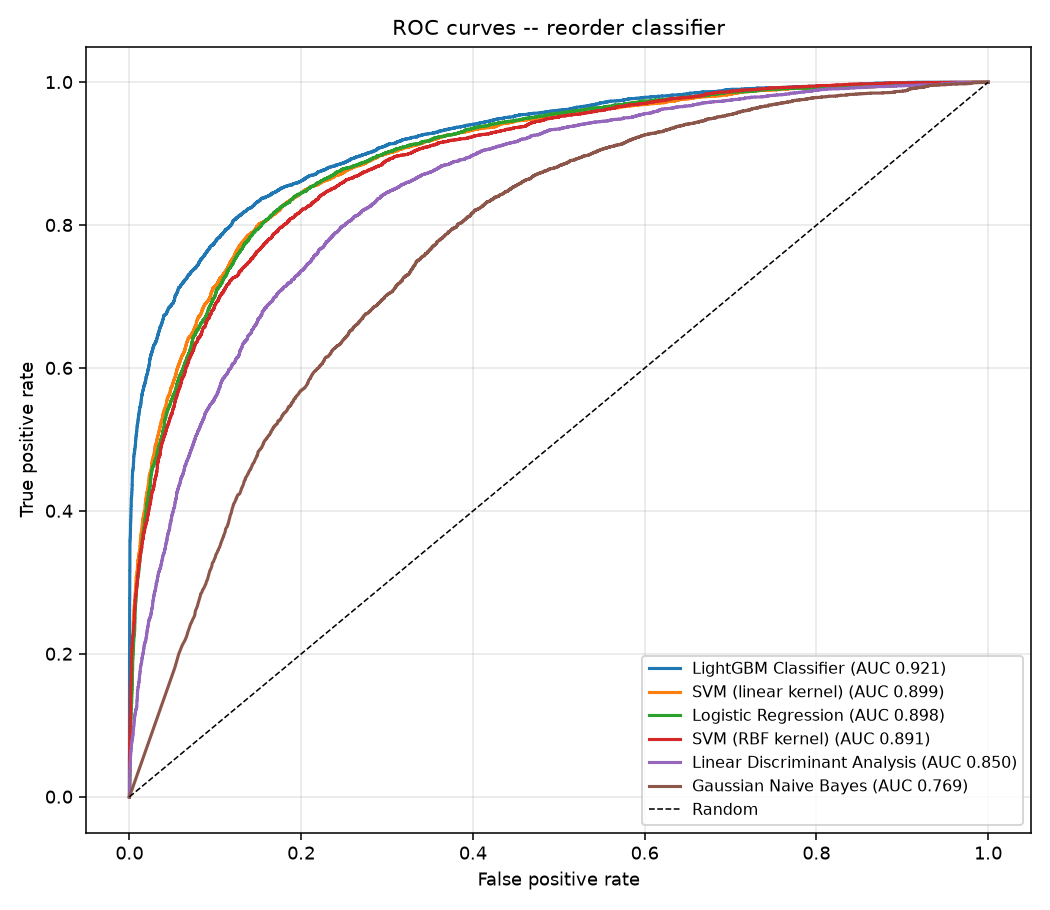

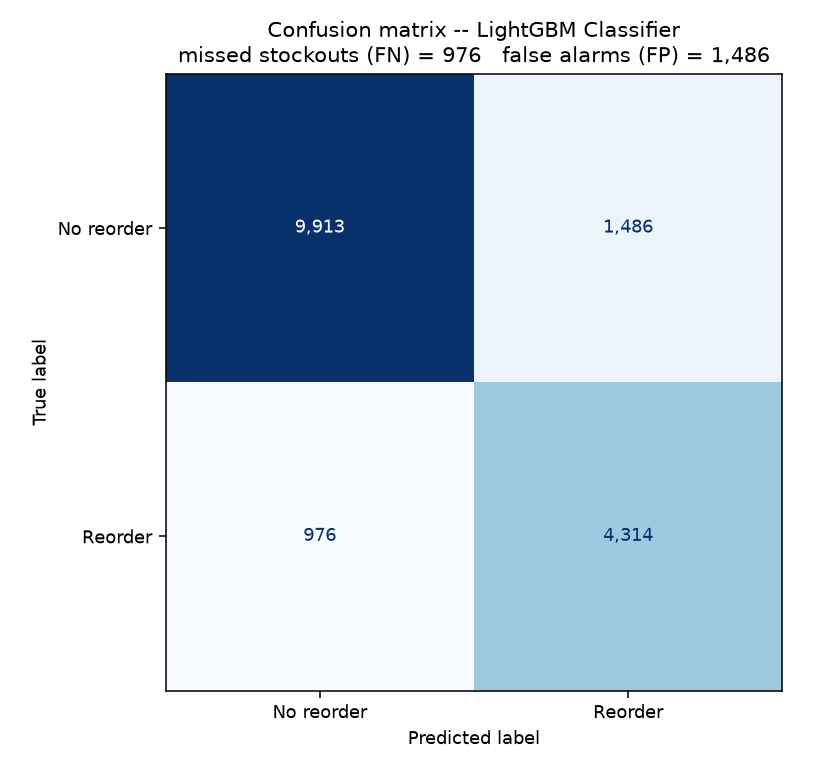

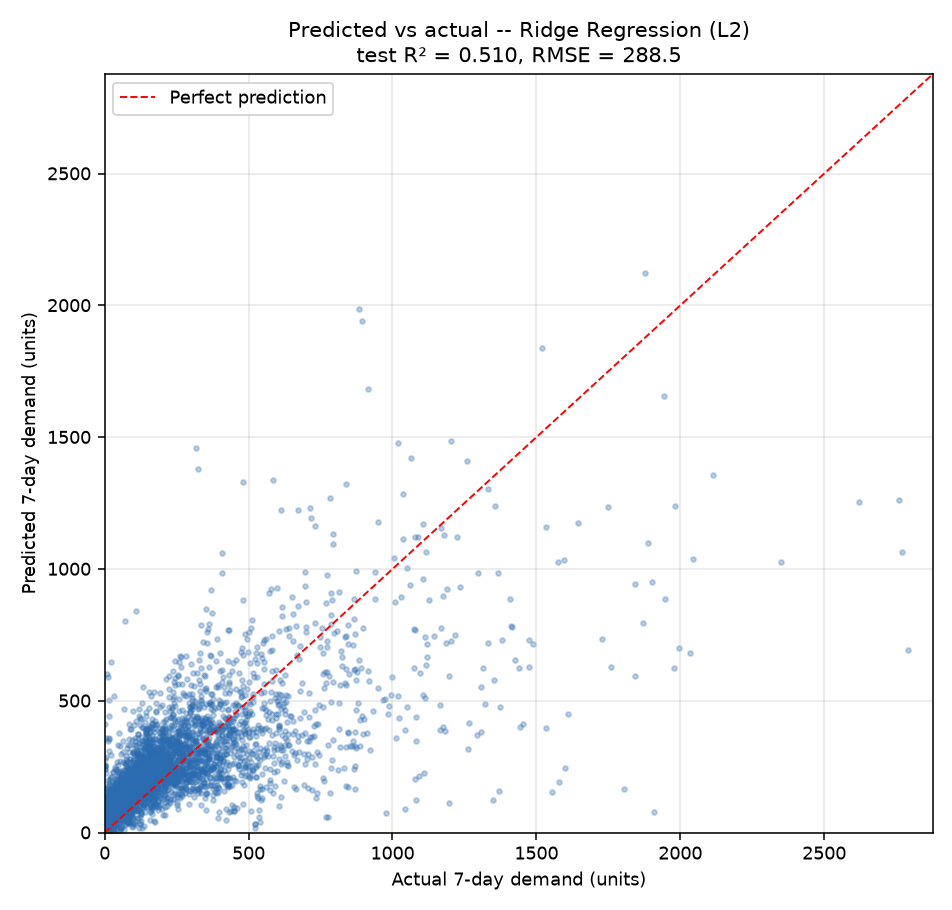

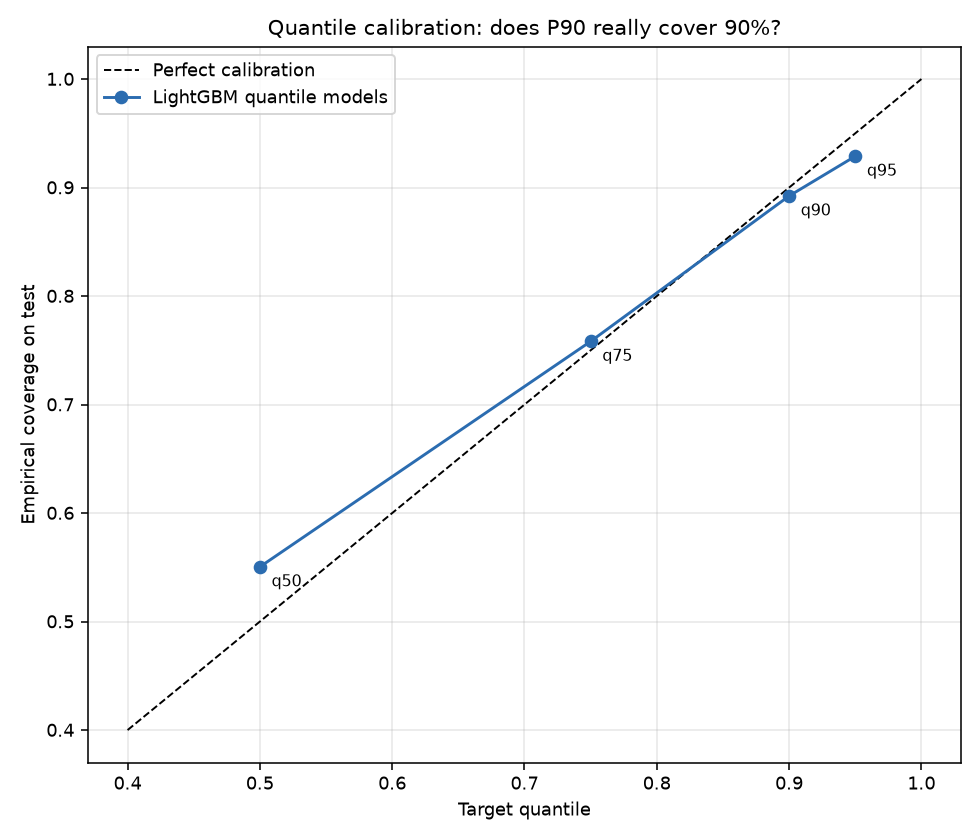

In [7]:
for f in ['model_regression_rmse.png','model_regression_r2.png',
          'model_classification_f1.png','model_roc_curves.png',
          'model_confusion_matrix.png','model_predicted_vs_actual.png',
          'model_quantile_calibration.png']:
    display(Image(filename=str(FIGS / f)))